# Домашнее задание 2. Линейные модели и честная валидация

### Андроник Диана, ПМИ 3 курс
---


## === Часть 1. Своя линейная регрессия ===

[Данные - California Housing Prices](https://www.kaggle.com/datasets/camnugent/california-housing-prices/data), предсказываем цену дома `medianHouseValue`

---

### 1. Оформить обучение как класс, совместимый с *sklearn*: методы `fit`, `predict`, `get_params`, `set_params`

In [ ]:
import numpy as np
from sklearn.base import BaseEstimator, RegressorMixin


class MyLinearRegression(BaseEstimator, RegressorMixin):
    def __init__(
        self,
        lr=0.1,
        alpha=0.0,
        reg=True,
        loss="mse",
        delta=1.35,
        mode="batch",
        batch_size=32,
        max_iter=200,
        random_state=42
    ):
        self.lr = lr
        self.alpha = alpha
        self.reg = reg
        self.loss = loss
        self.delta = delta
        self.mode = mode
        self.batch_size = batch_size
        self.max_iter = max_iter
        self.random_state = random_state

    def fit(self, X, y):
        X = np.asarray(X, dtype=np.float64)
        y = np.asarray(y, dtype=np.float64).ravel()

        n_samples, n_features = X.shape

        self.w_ = np.zeros(n_features, dtype=np.float64)
        self.b_ = 0.0
        self.loss_history_ = []

        for _ in range(self.max_iter):
            y_pred = X @ self.w_ + self.b_
            error = y_pred - y

            grad_w = (2.0 / n_samples) * (X.T @ error)
            grad_b = (2.0 / n_samples) * np.sum(error)

            if self.reg and self.alpha > 0:
                grad_w += 2.0 * self.alpha * self.w_

            self.w_ -= self.lr * grad_w
            self.b_ -= self.lr * grad_b

            new_error = X @ self.w_ + self.b_ - y
            current_loss = np.mean(new_error ** 2)

            if self.reg and self.alpha > 0:
                current_loss += self.alpha * np.sum(self.w_ ** 2)
            self.loss_history_.append(current_loss)

        return self

    

    def predict(self, X):
        X = np.asarray(X, dtype=np.float64)
        return X @ self.w_ + self.b_

---
### 2. Проверить совместимость делом: передать свой класс в `cross_val_score` и в `GridSearchCV`, подобрать `alpha` и `lr` перебором

In [27]:
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline


RANDOM_STATE = 42


data = fetch_california_housing(as_frame=True)
X, y = data.data, data.target


X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=RANDOM_STATE
)

pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", MyLinearRegression(
        max_iter=800,
        random_state=RANDOM_STATE
    ))
])

cv_scores = cross_val_score(pipeline, X_train, y_train, cv=5)


print("R^2 на каждом фолде:", np.round(cv_scores, 4))
print(f"Средний R^2 на CV: {cv_scores.mean():.4f}")


param_grid = {
    "model__lr": [0.1, 0.2, 0.3, 0.38, 0.4, 0.42],
    "model__alpha": [0.0, 0.0001, 0.0005, 0.001, 0.01]
}

grid_search = GridSearchCV(estimator=pipeline, param_grid=param_grid, cv=5)

grid_search.fit(X_train, y_train)

print("Лучшие параметры:", grid_search.best_params_)
print(f"Лучший средний R^2 на CV: {grid_search.best_score_:.4f}")

test_r2 = grid_search.score(X_test, y_test)
print(f"Лучший R^2 на тесте: {test_r2:.4f}")


R^2 на каждом фолде: [0.6201 0.613  0.6134 0.6107 0.6002]
Средний R^2 на CV: 0.6115
Лучшие параметры: {'model__alpha': 0.0, 'model__lr': 0.4}
Лучший средний R^2 на CV: 0.6115
Лучший R^2 на тесте: 0.5758


---
### 3. Поддержать две функции потерь на выбор: `MSE` и `Huber`. Формулу градиента `Huber` вывести самому и записать в ноутбуке

**Вывод формулы градиента Huber:**

Функция потерь Huber-а:

$$
L_\delta(e) = 
\begin{cases} 
\frac{1}{2} (\hat{y} - y)^2, & |\hat{y} - y| \le \delta \\ 
\delta \left(|\hat{y} - y| - \frac{1}{2}\delta\right), & |\hat{y} - y| > \delta 
\end{cases}
$$

Пусть $e := \hat{y} - y$.

$$
\displaystyle \frac{\partial L}{\partial w} = \frac{\partial L}{\partial e} \cdot \frac{\partial e}{\partial w}, \ \ \ \ \
\displaystyle \frac{\partial L}{\partial b} = \frac{\partial L}{\partial e} \cdot \frac{\partial e}{\partial b}
$$

1) - $\displaystyle |e| <= \delta \Rightarrow \frac{\partial L}{\partial e} = e$

   - $ \displaystyle |e| > \delta \Rightarrow \frac{\partial L}{\partial e} = \delta \cdot sign(e)$

Получили производную функции потерь по остаткам:
$$
\psi(e) = \frac{\partial L_\delta}{\partial e} = 
\begin{cases} 
e, & |e| \le \delta \\ 
\delta \cdot \text{sign}(e), & |e| > \delta 
\end{cases}
$$

2) $ \ \displaystyle \hat{y} = X w + b \Rightarrow e = Xw + b - y \Rightarrow \frac{\partial e}{\partial w} = X^T$

3) $ \ \displaystyle \frac{\partial e}{\partial b} = 1$

Отсюда формулы градиентов для $n$ объектов:

- $ \displaystyle \nabla_w L = \frac{1}{n} X^T \psi(e), \ \texttt{а с учётом регуляризации} \ \  \frac{1}{n} X^T \psi(e) + 2 \alpha w$

- $ \displaystyle \nabla_b L = \frac{1}{n} \sum_{i=1}^n \psi(e_i) $

**Поддержка двух функций потерь:**

In [28]:

def fit(self, X, y):
    X = np.asarray(X, dtype=np.float64)
    y = np.asarray(y, dtype=np.float64).ravel()

    n_samples, n_features = X.shape

    self.n_features_in_ = n_features
    self.w_ = np.zeros(n_features, dtype=np.float64)
    self.b_ = 0.0
    self.loss_history_ = []

    for _ in range(self.max_iter):
        y_pred = X @ self.w_ + self.b_
        error = y_pred - y

        if self.loss == "mse":
            grad_w = (2.0 / n_samples) * (X.T @ error)
            grad_b = 2.0 * np.mean(error)
        

        else:  # Huber
            abs_error = np.abs(error)

            psi = np.where(
                abs_error <= self.delta,
                error,
                self.delta * np.sign(error)
            )

            grad_w = (X.T @ psi) / n_samples
            grad_b = np.mean(psi)



        if self.reg and self.alpha > 0:
            grad_w += 2.0 * self.alpha * self.w_

        self.w_ -= self.lr * grad_w
        self.b_ -= self.lr * grad_b

        new_error = X @ self.w_ + self.b_ - y
        abs_new_error = np.abs(new_error)


        if self.loss == "mse":
            current_loss = np.mean(new_error ** 2)
            
        else: # Huber
            sample_loss = np.where(
                abs_new_error <= self.delta,
                0.5 * (new_error ** 2),
                self.delta * (
                    abs_new_error - 0.5 * self.delta
                )
            )
            current_loss = np.mean(sample_loss)

        if self.reg and self.alpha > 0:
            current_loss += self.alpha * np.sum(self.w_ ** 2)

        self.loss_history_.append(current_loss)

    return self

---
### 4. Поддержать три режима: полный градиент, стохастический и мини-пакетный. Матрично-векторные операции, без циклов по объектам

In [29]:
import numpy as np
from sklearn.base import BaseEstimator, RegressorMixin


class MyLinearRegression(BaseEstimator, RegressorMixin):
    def __init__(
        self,
        lr=0.1,
        alpha=0.0,
        reg=True,
        loss="mse",
        delta=1.35,
        mode="batch",
        batch_size=32,
        max_iter=200,
        random_state=RANDOM_STATE
    ):
        self.lr = lr
        self.alpha = alpha
        self.reg = reg
        self.loss = loss
        self.delta = delta
        self.mode = mode
        self.batch_size = batch_size
        self.max_iter = max_iter
        self.random_state = random_state



    def _calc_gradients(self, X_batch, y_batch):
        n_batch = X_batch.shape[0]
        error = X_batch @ self.w_ + self.b_ - y_batch

        if self.loss == "mse":
            grad_w = (2.0 / n_batch) * (X_batch.T @ error)
            grad_b = 2.0 * np.mean(error)
        else:  # Huber
            abs_error = np.abs(error)
            psi = np.where(
                abs_error <= self.delta,
                error,
                self.delta * np.sign(error)
            )
            grad_w = (X_batch.T @ psi) / n_batch
            grad_b = np.mean(psi)
        

        if self.reg and self.alpha > 0:
            grad_w += 2.0 * self.alpha * self.w_

        return grad_w, grad_b



    def _calc_loss(self, X, y):
        error = X @ self.w_ + self.b_ - y

        if self.loss == "mse":
            current_loss = np.mean(error ** 2)
            
        else:  # Huber
            abs_error = np.abs(error)
            sample_loss = np.where(
                abs_error <= self.delta,
                0.5 * (error ** 2),
                self.delta * (abs_error - 0.5 * self.delta)
            )
            current_loss = np.mean(sample_loss)
        

        if self.reg and self.alpha > 0:
            current_loss += self.alpha * np.sum(self.w_ ** 2)

        return current_loss



    def fit(self, X, y):
        X = np.asarray(X, dtype=np.float64)
        y = np.asarray(y, dtype=np.float64).ravel()

        n_samples, n_features = X.shape
        rng = np.random.default_rng(self.random_state)

        self.n_features_in_ = n_features
        self.w_ = np.zeros(n_features, dtype=np.float64)
        self.b_ = 0.0
        self.loss_history_ = [self._calc_loss(X, y)]

        for _ in range(self.max_iter):
            if self.mode == "batch":
                grad_w, grad_b = self._calc_gradients(X, y)
                self.w_ -= self.lr * grad_w
                self.b_ -= self.lr * grad_b

            else :
                indices = rng.permutation(n_samples)
                size = 1 if self.mode == "sgd" else self.batch_size
                batches = [indices[i : i + size] for i in range(0, n_samples, size)]

                for batch in batches:
                    grad_w, grad_b = self._calc_gradients(X[batch], y[batch])
                    self.w_ -= self.lr * grad_w
                    self.b_ -= self.lr * grad_b


            current_loss = self._calc_loss(X, y)
            self.loss_history_.append(current_loss)

        return self



    def predict(self, X):
        X = np.asarray(X, dtype=np.float64)
        return X @ self.w_ + self.b_

---
### 5. Поддержать L2-регуляризацию и возможность её отключить; сохранять историю потерь по эпохам и построить кривые обучения трёх режимов на одном графике

1) L2-регуляризация поддерживается: если передать `reg=False` (или `alpha=0.0`), L2-регуляризация отключается, если передать `reg=True` и `alpha > 0`, регуляризация учитывается (в градиенте и в функции потер)

2) История потерь сохраняется в `self.loss_history_`, причём первая точка истории — ошибка *до* обучения 


#### Кривые обучения:

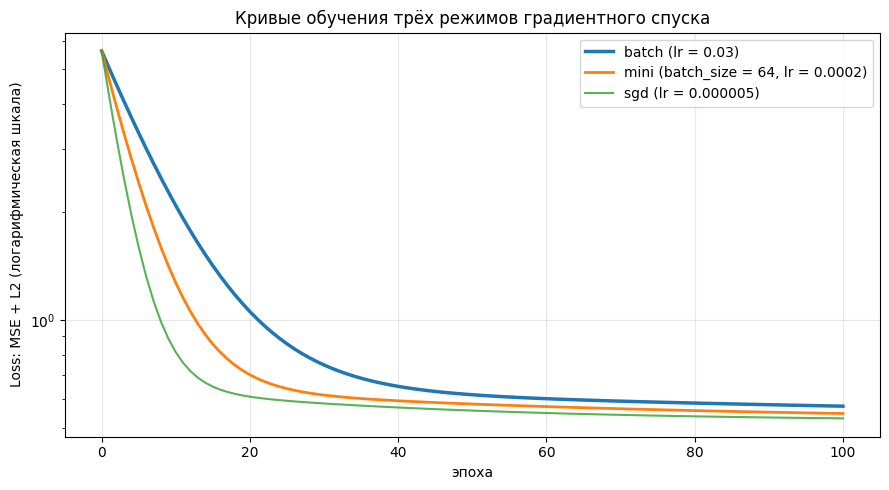

Веса c L2 (reg=True):  [ 0.8439  0.1527 -0.2276  0.2545  0.0078 -0.043  -0.6407 -0.6103]
Веса без L2 (reg=False): [ 0.8584  0.1499 -0.2538  0.2823  0.007  -0.0434 -0.6849 -0.6559]
Норма весов с регуляризацией = 1.2794, без = 1.3434


In [30]:
import matplotlib.pyplot as plt

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

n_epochs = 100
alpha_val = 0.001

m_batch = MyLinearRegression(
    mode="batch", lr=0.03, alpha=alpha_val, reg=True, max_iter=n_epochs, random_state=42
).fit(X_train_scaled, y_train)

m_mini = MyLinearRegression(
    mode="mini", batch_size=64, lr=0.0002, alpha=alpha_val, reg=True, max_iter=n_epochs, random_state=42
).fit(X_train_scaled, y_train)

m_sgd = MyLinearRegression(
    mode="sgd", lr=0.000005, alpha=alpha_val, reg=True, max_iter=n_epochs, random_state=42
).fit(X_train_scaled, y_train)

fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(m_batch.loss_history_, lw=2.5, label="batch (lr = 0.03)")
ax.plot(m_mini.loss_history_, lw=2, label="mini (batch_size = 64, lr = 0.0002)")
ax.plot(m_sgd.loss_history_, lw=1.5, alpha=0.8, label="sgd (lr = 0.000005)")

ax.set_yscale("log")
ax.set_xlabel("эпоха")
ax.set_ylabel("Loss: MSE + L2 (логарифмическая шкала)")
ax.set_title("Кривые обучения трёх режимов градиентного спуска")
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

m_reg_on = MyLinearRegression(
    mode="batch", lr=0.1, alpha=0.01, reg=True, max_iter=n_epochs, random_state=42
).fit(X_train_scaled, y_train)

m_reg_off = MyLinearRegression(
    mode="batch", lr=0.1, alpha=0.01, reg=False, max_iter=n_epochs, random_state=42
).fit(X_train_scaled, y_train)

print("Веса c L2 (reg=True): ", np.round(m_reg_on.w_, 4))
print("Веса без L2 (reg=False):", np.round(m_reg_off.w_, 4))
print(f"Норма весов с регуляризацией = {np.linalg.norm(m_reg_on.w_):.4f}, без = {np.linalg.norm(m_reg_off.w_):.4f}")

---
### 6. Испортить данные выбросами: взять `2–3%` объектов и умножить их целевое значение на `10`. Обучить обе версии и показать, насколько разъехались веса и качество. Объяснить, почему Huber держится

In [31]:
rng = np.random.default_rng(42)

y_train = np.asarray(y_train, dtype=np.float64).copy()
y_test = np.asarray(y_test, dtype=np.float64).copy()

y_train_out = y_train.copy()
n_out = int(0.025 * len(y_train_out))
out_idx = rng.choice(len(y_train_out), size=n_out, replace=False)
y_train_out[out_idx] *= 10.0

mse_clean = MyLinearRegression(
    loss="mse", mode="batch", lr=0.1, alpha=0.001, max_iter=500, random_state=42
).fit(X_train_scaled, y_train)

huber_clean = MyLinearRegression(
    loss="huber", delta=1.35, mode="batch", lr=0.1, alpha=0.001, max_iter=500, random_state=42
).fit(X_train_scaled, y_train)

mse_out = MyLinearRegression(
    loss="mse", mode="batch", lr=0.1, alpha=0.001, max_iter=500, random_state=42
).fit(X_train_scaled, y_train_out)

huber_out = MyLinearRegression(
    loss="huber", delta=1.35, mode="batch", lr=0.1, alpha=0.001, max_iter=500, random_state=42
).fit(X_train_scaled, y_train_out)

mse_w_diff = np.linalg.norm(mse_clean.w_ - mse_out.w_)
huber_w_diff = np.linalg.norm(huber_clean.w_ - huber_out.w_)

mse_b_diff = abs(mse_clean.b_ - mse_out.b_)
huber_b_diff = abs(huber_clean.b_ - huber_out.b_)

print("=== Сравнение качества R^2 на чистом тесте ===")
print(f"MSE   (обучение на чистых):   R^2 = {mse_clean.score(X_test_scaled, y_test):.4f}")
print(f"MSE   (обучение с выбросами): R^2 = {mse_out.score(X_test_scaled, y_test):.4f}")
print(f"Huber (обучение на чистых):   R^2 = {huber_clean.score(X_test_scaled, y_test):.4f}")
print(f"Huber (обучение с выбросами): R^2 = {huber_out.score(X_test_scaled, y_test):.4f}")

print("\n=== Насколько разъехались веса и свободный член ===")
print(f"MSE:   ||w_clean - w_out||_2 = {mse_w_diff:.4f}, |b_clean - b_out| = {mse_b_diff:.4f}")
print(f"Huber: ||w_clean - w_out||_2 = {huber_w_diff:.4f}, |b_clean - b_out| = {huber_b_diff:.4f}")

print("\nВеса MSE (чистые):    ", np.round(mse_clean.w_, 3))
print("Веса MSE (выбросы):   ", np.round(mse_out.w_, 3))
print("Веса Huber (чистые):  ", np.round(huber_clean.w_, 3))
print("Веса Huber (выбросы): ", np.round(huber_out.w_, 3))

=== Сравнение качества R^2 на чистом тесте ===
MSE   (обучение на чистых):   R^2 = 0.5762
MSE   (обучение с выбросами): R^2 = 0.3939
Huber (обучение на чистых):   R^2 = 0.5723
Huber (обучение с выбросами): R^2 = 0.5740

=== Насколько разъехались веса и свободный член ===
MSE:   ||w_clean - w_out||_2 = 0.3745, |b_clean - b_out| = 0.4495
Huber: ||w_clean - w_out||_2 = 0.0094, |b_clean - b_out| = 0.0376

Веса MSE (чистые):     [ 0.854  0.124 -0.293  0.336 -0.002 -0.041 -0.882 -0.855]
Веса MSE (выбросы):    [ 1.011  0.103 -0.354  0.398 -0.002 -0.054 -1.109 -1.092]
Веса Huber (чистые):   [ 0.891  0.129 -0.314  0.352  0.007 -0.044 -0.775 -0.759]
Веса Huber (выбросы):  [ 0.889  0.127 -0.31   0.346  0.005 -0.044 -0.778 -0.764]


#### **Почему Huber держится (а MSE - нет):**

1. **Поведение MSE:** В функции потерь $\text{MSE} = \frac{1}{n}\sum (\hat{y}_i - y_i)^2$ остатки возводятся в квадрат, а градиент линейно пропорционален величине ошибки: $\frac{\partial L}{\partial e_i} = 2 e_i$. Когда мы умножаем целевую переменную $y_i$ на 10, остаток $e_i$ вырастает почти в 10 раз, а квадрат ошибки в функции потерь — в **100 раз**. Из-за этого свободный член $b$ и веса $w$ сильно смещаются вверх, а $R^2$ на тестовой выборке резко падает

2. **Поведение Huber:** Функция Huber-а при $|e_i| > \delta$ переходит с параболы на прямую линию. Её производная по остатку $\psi(e_i)$ **ограничена сверху и снизу константой $\pm \delta$**:
   $$\psi(e_i) = \delta \cdot \text{sign}(e_i) \quad \text{при } |e_i| > \delta$$
   Поэтому независимо от того, насколько большим оказался выброс, вклад такого объекта в градиент обрезается порогом $\delta$. Поэтому выбросы не могут "утянуть" за собой веса модели

---
### 7. Сверить обе версии с `sklearn`: `Ridge` против вашей MSE-версии, `HuberRegressor` против Huber-версии — здесь нужно объяснить расхождение

In [32]:
from sklearn.linear_model import Ridge, HuberRegressor

n_samples = X_train_scaled.shape[0]
alpha = 0.01

my_mse = MyLinearRegression(
    loss="mse", mode="batch", lr=0.1, alpha=alpha, reg=True, max_iter=2000, random_state=42
).fit(X_train_scaled, y_train)

sk_ridge = Ridge(alpha=alpha * n_samples).fit(X_train_scaled, y_train)

print("=== 1. Сверяем Ridge и нашу MSE-версию ===")
print("Наши веса:  ", np.round(my_mse.w_, 8))
print("Веса Ridge: ", np.round(sk_ridge.coef_, 8))
print(f"Наш сдвиг b: {my_mse.b_:.5f}, сдвиг Ridge: {sk_ridge.intercept_:.5f}")
print(f"Максимальное расхождение весов max|w_my - w_ridge|: {np.max(np.abs(my_mse.w_ - sk_ridge.coef_)):.2e}")

delta_val = 1.35
my_huber = MyLinearRegression(
    loss="huber", delta=delta_val, mode="batch", lr=0.1, alpha=alpha, reg=True, max_iter=2000, random_state=42
).fit(X_train_scaled, y_train)

sk_huber = HuberRegressor(
    epsilon=delta_val, alpha=alpha * n_samples, max_iter=2000
).fit(X_train_scaled, y_train)

print("\n=== 2. Сверяем HuberRegressor и наш Huber ===")
print("Наши веса:           ", np.round(my_huber.w_, 4))
print("Веса HuberRegressor: ", np.round(sk_huber.coef_, 4))
print(f"Наш сдвиг b_: {my_huber.b_:.4f}, сдвиг HuberRegressor: {sk_huber.intercept_:.4f}")
print(f"Норма разности ||w_my - w_sk||_2: {np.linalg.norm(my_huber.w_ - sk_huber.coef_):.4f}")
print(f"Оценка масштаба остатков sigma (sk_huber.scale_): {sk_huber.scale_:.4f}")
print(f"Эффективный порог в HuberRegressor (epsilon * scale_): {delta_val * sk_huber.scale_:.4f} (против нашего delta = {delta_val})")

=== 1. Сверяем Ridge и нашу MSE-версию ===
Наши веса:   [ 0.84360639  0.13329462 -0.26189398  0.29974856  0.00121408 -0.04125213
 -0.78881064 -0.76009692]
Веса Ridge:  [ 0.84360639  0.13329462 -0.26189398  0.29974856  0.00121408 -0.04125213
 -0.78881064 -0.76009692]
Наш сдвиг b: 2.07195, сдвиг Ridge: 2.07195
Максимальное расхождение весов max|w_my - w_ridge|: 2.42e-11

=== 2. Сверяем HuberRegressor и наш Huber ===
Наши веса:            [ 0.8536  0.1386 -0.2358  0.2613  0.0106 -0.0435 -0.651  -0.6303]
Веса HuberRegressor:  [ 0.9029  0.1038 -0.3256  0.3635  0.0092 -0.2014 -0.6986 -0.6943]
Наш сдвиг b_: 2.0378, сдвиг HuberRegressor: 1.9689
Норма разности ||w_my - w_sk||_2: 0.2312
Оценка масштаба остатков sigma (sk_huber.scale_): 0.3715
Эффективный порог в HuberRegressor (epsilon * scale_): 0.5015 (против нашего delta = 1.35)


#### **Объяснение расхождения `HuberRegressor` против `Huber-версии`:**

В [документации](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.HuberRegressor.html) сказано:

> *"The Huber Regressor optimizes the squared loss for the samples where **|(y - Xw - c) / sigma| < epsilon** and the absolute loss for the samples where **|(y - Xw - c) / sigma| > epsilon**, where the model coefficients **w**, the intercept **c** and the scale **sigma** are parameters to be optimized. The parameter sigma makes sure that if **y** is scaled up or down by a certain factor, one does not need to rescale **epsilon** to achieve the same robustness."*

Отличие от нашей реализации:
* `Наша модель` сравнивает с порогом $\delta$ ($\text{epsilon}$) остаток напрямую: квадратичная ошибка применяется там, где $\vert{}y - Xw - b\vert{} \le \delta$, а линейная — где $\vert{}y - Xw - b\vert{} > \delta$.
* `HuberRegressor` же одновременно с весами $w$ и сдвигом $c$ обучает дополнительный параметр масштаба остатков `sigma`. Перед тем как применить порог `epsilon`, он **делит каждый остаток на `sigma`**: проверяется условие $\vert{}(y - Xw - c) / \text{sigma}\vert{} < \text{epsilon}$ (что равносильно порогу $\text{epsilon} \cdot \text{sigma}$ для обычных остатков). Это нужно для того, чтобы при изменении масштаба целевой переменной $y$ не приходилось вручную переподбирать `epsilon`.

**Почему это влияет на веса:**
На наших данных `HuberRegressor` оценил масштаб остатков `sigma` (`sk_huber.scale_`) в $0.3715$, а не в $1.0$. Из-за деления на `sigma` он переключается с квадратичной функции потерь на линейную при другом фактическом размере ошибки, чем наш класс, в результате чего итоговые веса отличаются.

---
---

## === Часть 2. Честная валидация ===

[Датасет - Airline Satisfaction Data](https://www.kaggle.com/datasets/arseniyshutko/binary-aviation-satisfaction-129k), предсказываем `satisfaction` `(True = Satisfied, False = Not Satisfied)` - удовлетворён ли пассажир


---
### 0. Посмотрим на датасет, чуть-чуть причешем

In [33]:
import kagglehub
import pandas as pd
import os

path = kagglehub.dataset_download("arseniyshutko/binary-aviation-satisfaction-129k")
df = pd.read_csv(os.path.join(path, "data.csv"))

print("Размер:", df.shape)

print("\nТипы колонок и пропуски:")
print(df.info())

print("\nПервые 3 строки:")
display(df.head(3))

print("\nРаспределение целевой переменной:")
print(df.iloc[:, -1].value_counts(dropna=False))


Размер: (129880, 22)

Типы колонок и пропуски:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 129880 entries, 0 to 129879
Data columns (total 22 columns):
 #   Column                             Non-Null Count   Dtype  
---  ------                             --------------   -----  
 0   Gender                             129880 non-null  object 
 1   Customer Type                      129880 non-null  object 
 2   Age                                129880 non-null  int64  
 3   Type of Travel                     129880 non-null  object 
 4   Class                              129880 non-null  object 
 5   Flight Distance                    129880 non-null  int64  
 6   Inflight wifi service              129880 non-null  int64  
 7   Departure/Arrival time convenient  129880 non-null  int64  
 8   Ease of Online booking             129880 non-null  int64  
 9   Gate location                      129880 non-null  int64  
 10  Food and drink                     129880 non-null  int64

,Gender,Customer Type,Age,Type of Travel,Class,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,...,Seat comfort,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,satisfaction
0,Male,Loyal Customer,13,Personal Travel,Eco Plus,460,3,4,3,1,...,5,5,4,3,4,4,5,25,18.0,False
1,Male,disloyal Customer,25,Business travel,Business,235,3,2,3,3,...,1,1,1,5,3,1,1,1,6.0,False
2,Female,Loyal Customer,26,Business travel,Business,1142,2,2,2,2,...,5,5,4,3,4,4,5,0,0.0,True



Распределение целевой переменной:
satisfaction
False    73452
True     56428
Name: count, dtype: int64


In [34]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline


# Не будем заморачиваться, и просто удалим пропуски (их очень мало)
df = df.dropna().reset_index(drop=True)


# 1 - недовольный пассажир, 0 - довольный
y = (~df["satisfaction"]).astype(int)

X = df.drop(columns=["satisfaction"])
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)


numeric_cols = X.select_dtypes(include=["number"]).columns
cat_cols = X.select_dtypes(include=["object", "category"]).columns


preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols)
    ]
)


pipe = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(
        penalty="l2",
        C=1.0,
        max_iter=1000,
        random_state=42
    ))
])


print(f"Размер обучающей выборки: {X_train.shape}")
print(f"Доля недовольных пассажиров (класс 1) в train: {y_train.mean():.4f}")

Размер обучающей выборки: (103589, 21)
Доля недовольных пассажиров (класс 1) в train: 0.5655


---
### 1. Обосновать выбор метрики для вашей задачи. Не «взял accuracy, потому что все так делают», а рассуждение о том, какая ошибка дороже

Классы относительно сбалансированы (~43.5% довольных (`0`) и ~56.5% недовольных (`1`))

* **Какая ошибка дороже:**
  * **False Negative (`FN` — модель предсказала, что пассажир доволен (0), а он на самом деле ушёл расстроенным (1)):** компания может потерять лояльность клиента. Это плохой сценарий для бизнеса.
  * **False Positive (`FP` — модель предсказала, что пассажир недоволен (1), хотя он доволен (0)):** компания может потратить ресурсы на лишнюю проверку или ненужные меры по улучшению его опыта.
  
* **Выбор метрик:** 
  1. Для бизнеса пропустить действительно недовольного пассажира обычно дороже, чем ошибочно заподозрить недовольство у довольного $\Rightarrow$ важно минимизировать `FN` $\Rightarrow$ основной метрикой выбрираем `Recall `, тк она "штрафует" за `FN`

  2. Однако модель может добиться высокого `Recall`, относя всех пассажиров к недовольным. Поэтому дополнительно будем отслеживать `Precision` и `F1`, чтобы оценивать количество ложных срабатываний и общий баланс качества классификации. А для оценки способности модели различать классы при различных порогах классификации - `ROC-AUC` и `PR-AUC`.

---
### 2. Выбрать и обосновать схему кросс-валидации. Если в данных есть группы или время — использовать соответствующую схему и объяснить, почему обычная не подходит


* Групп или времени в данных нет
* **Почему обычный `KFold` не подходит:** в задаче бинарной классификации при обычном случайном разбиении (`KFold`) соотношение классов (`1` — 56.5%, `0` — 43.5%) может колебаться от фолда к фолду. Т.к. метрики `Precision`, `F1-score` и `PR-AUC` чувствительны к базовой доле положительного класса, это приведёт к лишнему разбросу оценок качества $\Rightarrow$ используем стратифицированную кросс-валидацию (`StratifiedKFold`), которая сохраняет пропорции классов в каждом фолде приблизительно такими же, как во всей обучающей выборке (56.5% / 43.5%) 



In [37]:
from sklearn.model_selection import StratifiedKFold

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

for fold_idx, (train_idx, val_idx) in enumerate(cv.split(X_train, y_train), start=1):
    val_ratio = y_train.iloc[val_idx].mean()
    print(f"Фолд {fold_idx}: размер = {len(val_idx)}, доля недовольных (класс 1) = {val_ratio:.4f}")

Фолд 1: размер = 20718, доля недовольных (класс 1) = 0.5655
Фолд 2: размер = 20718, доля недовольных (класс 1) = 0.5655
Фолд 3: размер = 20718, доля недовольных (класс 1) = 0.5655
Фолд 4: размер = 20718, доля недовольных (класс 1) = 0.5655
Фолд 5: размер = 20717, доля недовольных (класс 1) = 0.5655


---
### 3. Подобрать силу регуляризации по кросс-валидации, построить график качества от alpha

`Alpha` будем подбирать по `F1`, которая учитывает и `Precision`, и `Recall`, тк Recall при стандартном пороге классификации 0.5 может приводить к выбору модели, которая чаще относит объекты к положительному классу. А смещение акцента в сторону `Recall` сделаем на этапе подбора порога классификации (6 пункт)

Лучший alpha: 100 (соответствует C = 0.01 в LogisticRegression)
Лучший средний F1 на CV:            0.8902
Средний Recall при лучшем alpha:    0.9046
Средний Precision при лучшем alpha: 0.8762
Средний ROC-AUC при лучшем alpha:   0.9261
Средний PR-AUC при лучшем alpha:    0.9079


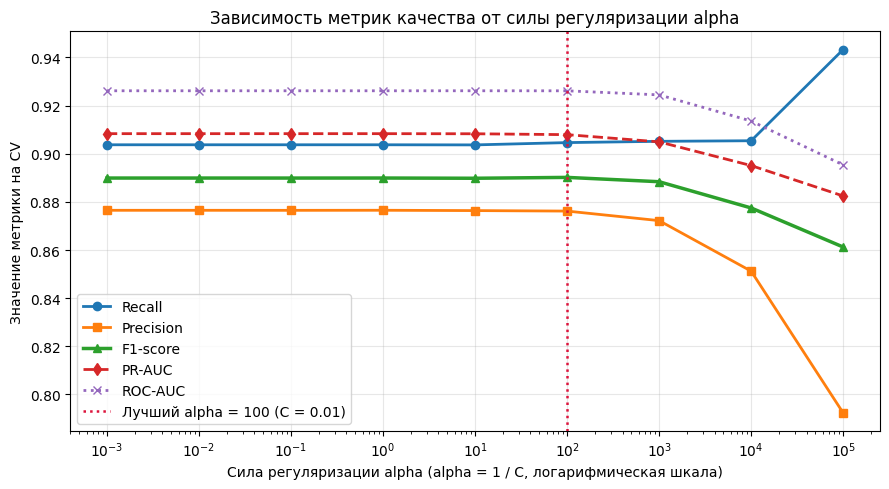

In [49]:
alphas = np.logspace(-3, 5, 9)


param_grid = {
    "model__C": 1.0 / alphas
}

scoring = {
    "recall": "recall",
    "precision": "precision",
    "f1": "f1",
    "roc_auc": "roc_auc",
    "pr_auc": "average_precision"
}

grid_search = GridSearchCV(
    estimator=pipe,
    param_grid=param_grid,
    cv=cv,
    scoring=scoring,
    refit="f1",
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

best_idx = grid_search.best_index_
best_alpha = alphas[best_idx]
best_c = 1.0 / best_alpha

print(f"Лучший alpha: {best_alpha:.4g} (соответствует C = {best_c:.4g} в LogisticRegression)")
print(f"Лучший средний F1 на CV:            {grid_search.cv_results_['mean_test_f1'][best_idx]:.4f}")
print(f"Средний Recall при лучшем alpha:    {grid_search.cv_results_['mean_test_recall'][best_idx]:.4f}")
print(f"Средний Precision при лучшем alpha: {grid_search.cv_results_['mean_test_precision'][best_idx]:.4f}")
print(f"Средний ROC-AUC при лучшем alpha:   {grid_search.cv_results_['mean_test_roc_auc'][best_idx]:.4f}")
print(f"Средний PR-AUC при лучшем alpha:    {grid_search.cv_results_['mean_test_pr_auc'][best_idx]:.4f}")

fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(alphas, grid_search.cv_results_["mean_test_recall"], marker="o", lw=2, label="Recall")
ax.plot(alphas, grid_search.cv_results_["mean_test_precision"], marker="s", lw=2, label="Precision")
ax.plot(alphas, grid_search.cv_results_["mean_test_f1"], marker="^", lw=2.5, label="F1-score")
ax.plot(alphas, grid_search.cv_results_["mean_test_pr_auc"], marker="d", lw=2, linestyle="--", label="PR-AUC")
ax.plot(alphas, grid_search.cv_results_["mean_test_roc_auc"], marker="x", lw=2, linestyle=":", label="ROC-AUC")

ax.axvline(best_alpha, color="crimson", linestyle=":", lw=1.8, label=f"Лучший alpha = {best_alpha:.4g} (C = {best_c:.4g})")

ax.set_xscale("log")
ax.set_xlabel("Сила регуляризации alpha (alpha = 1 / C, логарифмическая шкала)")
ax.set_ylabel("Значение метрики на CV")
ax.set_title("Зависимость метрик качества от силы регуляризации alpha")
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

---
### 4. Составить таблицу: строки — метрики, столбцы — фолды плюс среднее и стандартное отклонение

In [50]:
n_splits = grid_search.n_splits_
best_idx = grid_search.best_index_


metrics_map = {
    "Recall": "recall",
    "Precision": "precision",
    "F1-score": "f1",
    "ROC-AUC": "roc_auc",
    "PR-AUC": "pr_auc"
}


table_rows = {}
for label, key in metrics_map.items():
    fold_scores = [
        grid_search.cv_results_[f"split{i}_test_{key}"][best_idx]
        for i in range(n_splits)
    ]
    row = {f"Fold {i+1}": fold_scores[i] for i in range(n_splits)}
    row["Mean"] = np.mean(fold_scores)
    row["Std"] = np.std(fold_scores)
    table_rows[label] = row


cv_summary_df = pd.DataFrame(table_rows).T
display(cv_summary_df.round(4))

,Fold 1,Fold 2,Fold 3,Fold 4,Fold 5,Mean,Std
Recall,0.8989,0.9097,0.9046,0.9033,0.9066,0.9046,0.0036
Precision,0.8731,0.8789,0.8734,0.8792,0.8763,0.8762,0.0026
F1-score,0.8858,0.8940,0.8887,0.8911,0.8912,0.8902,0.0027
ROC-AUC,0.9231,0.9288,0.9249,0.9272,0.9267,0.9261,0.0019
PR-AUC,0.9058,0.9097,0.9069,0.9073,0.9100,0.9079,0.0016


---

### 5. Для задачи классификации построить ROC- и PR-кривые, объяснить разницу между ними на ваших данных

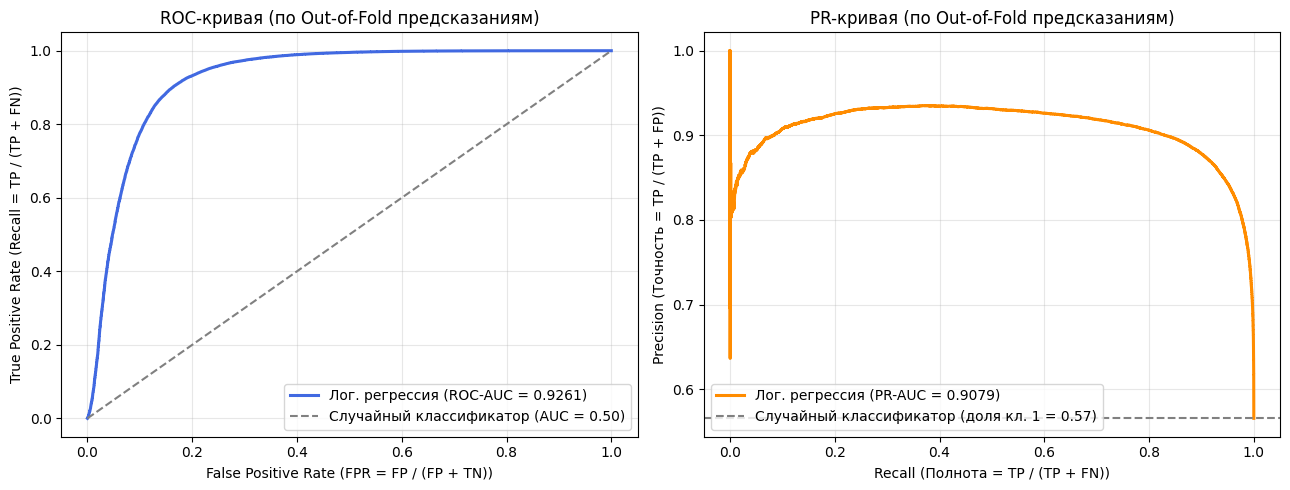

In [51]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import roc_curve, auc, precision_recall_curve, average_precision_score


best_pipe = grid_search.best_estimator_

# Получаем честные out-of-fold вероятности класса 1 на обучающей выборке
oof_proba = cross_val_predict(
    best_pipe, X_train, y_train, cv=cv, method="predict_proba", n_jobs=-1
)[:, 1]


fpr, tpr, roc_thresholds = roc_curve(y_train, oof_proba)
roc_auc_val = auc(fpr, tpr)


precision_vals, recall_vals, pr_thresholds = precision_recall_curve(y_train, oof_proba)
pr_auc_val = average_precision_score(y_train, oof_proba)


fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# ROC
axes[0].plot(fpr, tpr, color="royalblue", lw=2.2, label=f"Лог. регрессия (ROC-AUC = {roc_auc_val:.4f})")
axes[0].plot([0, 1], [0, 1], color="gray", linestyle="--", label="Случайный классификатор (AUC = 0.50)")
axes[0].set_xlabel("False Positive Rate (FPR = FP / (FP + TN))")
axes[0].set_ylabel("True Positive Rate (Recall = TP / (TP + FN))")
axes[0].set_title("ROC-кривая (по Out-of-Fold предсказаниям)")
axes[0].legend(loc="lower right")
axes[0].grid(True, alpha=0.3)

# PR
baseline_pr = y_train.mean() 
axes[1].plot(recall_vals, precision_vals, color="darkorange", lw=2.2, label=f"Лог. регрессия (PR-AUC = {pr_auc_val:.4f})")
axes[1].axhline(baseline_pr, color="gray", linestyle="--", label=f"Случайный классификатор (доля кл. 1 = {baseline_pr:.2f})")
axes[1].set_xlabel("Recall (Полнота = TP / (TP + FN))")
axes[1].set_ylabel("Precision (Точность = TP / (TP + FP))")
axes[1].set_title("PR-кривая (по Out-of-Fold предсказаниям)")
axes[1].legend(loc="lower left")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

#### Разница на наших данных:

* `ROC`-кривая: т.к. $\text{FPR} = \frac{\text{FP}}{\text{FP} + \text{TN}}$, она показывает, какую долю довольных пассажиров (класс 0, `TN`) мы ошибочно назвали недовольными.

* `PR`-кривая: т.к. $\text{Precision} = \frac{\text{TP}}{\text{TP} + \text{FP}}$, она не учитывает `TN` вообще и показывает, какая доля среди всех пассажиров, которых модель пометила как недовольных, действительно недовольна.

* `ROC-AUC = 0.9261` — модель хорошо различает довольных и недовольных пассажиров. `Average Precision = 0.9079`, что заметно выше базового уровня 0.5655 (доли класса 1).

* В нашей задаче `PR`-кривая особенно полезна, тк по ней мы напрямую видим, какую цену в виде падения `Precision` (лишних расходов на удержание довольных клиентов) нам придётся заплатить, если мы захотим увеличить `Recall`


---
### 6. Подобрать порог решения — не на тесте, а по out-of-fold предсказаниям на обучающей выборке

Стандартный порог (0.5000): Recall = 0.9046, Precision = 0.8762, F1 = 0.8902
Оптимальный порог (0.2833): Recall = 0.9680, Precision = 0.8207, F1 = 0.8883


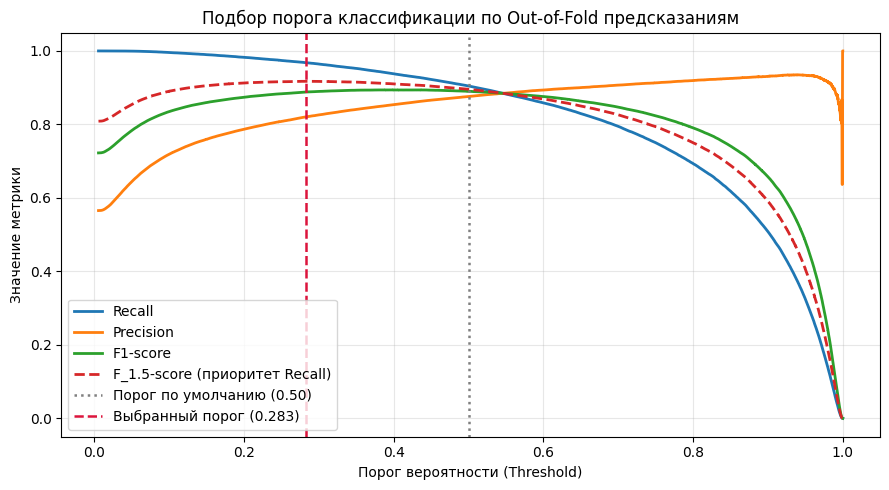

In [ ]:
from sklearn.metrics import precision_score, recall_score, f1_score


prec_t = precision_vals[:-1]
rec_t = recall_vals[:-1]


beta = 1.5
f1_scores = 2 * (prec_t * rec_t) / (prec_t + rec_t + 1e-10)
f_beta_scores = (1 + beta**2) * (prec_t * rec_t) / ((beta**2 * prec_t) + rec_t + 1e-10)


best_thr_idx = np.argmax(f_beta_scores)
optimal_threshold = pr_thresholds[best_thr_idx]


oof_pred_default = (oof_proba >= 0.5).astype(int)
print(
    f"Стандартный порог (0.5000): "
    f"Recall = {recall_score(y_train, oof_pred_default):.4f}, "
    f"Precision = {precision_score(y_train, oof_pred_default):.4f}, "
    f"F1 = {f1_score(y_train, oof_pred_default):.4f}"
)
print(
    f"Оптимальный порог ({optimal_threshold:.4f}): "
    f"Recall = {rec_t[best_thr_idx]:.4f}, "
    f"Precision = {prec_t[best_thr_idx]:.4f}, "
    f"F1 = {f1_scores[best_thr_idx]:.4f}"
)


plt.figure(figsize=(9, 5))
plt.plot(pr_thresholds, rec_t, label="Recall", lw=2)
plt.plot(pr_thresholds, prec_t, label="Precision", lw=2)
plt.plot(pr_thresholds, f1_scores, label="F1-score", lw=2)
plt.plot(pr_thresholds, f_beta_scores, label=f"F_{beta}-score (приоритет Recall)", lw=2, linestyle="--")


plt.axvline(0.5, color="gray", linestyle=":", lw=1.8, label="Порог по умолчанию (0.50)")
plt.axvline(optimal_threshold, color="crimson", linestyle="--", lw=1.8, label=f"Выбранный порог ({optimal_threshold:.3f})")


plt.xlabel("Порог вероятности (Threshold)")
plt.ylabel("Значение метрики")
plt.title("Подбор порога классификации по Out-of-Fold предсказаниям")
plt.legend(loc="lower left")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Т.к. пропуск недовольного клиента (`FN`) обходится бизнесу дороже ложной тревоги (`FP`), подбираем порог по максимуму $F_{1.5}$-меры на out-of-fold предсказаниях (в ней `Recall` важнее `Precision`).Снижение порога с `0.50` до `0.2833` (`optimal_threshold`) увеличило `Recall` с `0.9046` до `0.9680` при снижении `Precision` с `0.8762` до `0.8207`. При этом `F1` не сильно изменился (`0.8902` и `0.8883` соответственно). Таким образом, новый порог позволяет выявлять больше недовольных пассажиров ценой увеличения числа ложных срабатываний.

---

### 7. Оценить финальное качество на тестовой выборке. **Один раз**

In [56]:
from sklearn.metrics import recall_score, precision_score, f1_score, roc_auc_score


test_proba = best_pipe.predict_proba(X_test)[:, 1]


test_pred_optimal = (test_proba >= optimal_threshold).astype(int)
test_pred_default = (test_proba >= 0.5).astype(int)

test_results = pd.DataFrame({
    "Порог 0.50 (стандартный)": {
        "Recall": recall_score(y_test, test_pred_default),
        "Precision": precision_score(y_test, test_pred_default),
        "F1-score": f1_score(y_test, test_pred_default),
        "ROC-AUC": roc_auc_score(y_test, test_proba),
        "PR-AUC": average_precision_score(y_test, test_proba)
    },
    f"Порог {optimal_threshold:.4f} (подобранный на OOF)": {
        "Recall": recall_score(y_test, test_pred_optimal),
        "Precision": precision_score(y_test, test_pred_optimal),
        "F1-score": f1_score(y_test, test_pred_optimal),
        "ROC-AUC": roc_auc_score(y_test, test_proba),
        "PR-AUC": average_precision_score(y_test, test_proba)
    }
}).T

display(test_results.round(4))

,Recall,Precision,F1-score,ROC-AUC,PR-AUC
Порог 0.50 (стандартный),0.9034,0.8799,0.8915,0.927,0.9074
Порог 0.2833 (подобранный на OOF),0.9669,0.8230,0.8891,0.927,0.9074


**Согласованность с кросс-валидацией:**

* Метрики на *отложенной тестовой выборке* при выбранном пороге 0.2833 (`Recall = 0.9669, Precision = 0.8230, F1 = 0.8891, ROC-AUC = 0.9270, PR-AUC = 0.9074`) близки к оценкам, полученным на *out-of-fold* предсказаниях обучающей выборки (`Recall = 0.9680, Precision = 0.8207, F1 = 0.8883, ROC-AUC = 0.9261, PR-AUC = 0.9079`).

* Небольшие различия между метриками свидетельствуют о стабильности качества модели на данных, не использованных для её непосредственного обучения

--- 
### 8. Сравнить результат с baseline из первой работы

In [59]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import recall_score, precision_score, f1_score, roc_auc_score, average_precision_score


# 1) Наивный Baseline (DummyClassifier — всегда предсказывает мажорантный класс 1)
dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(X_train, y_train)
dummy_proba = dummy.predict_proba(X_test)[:, 1]
dummy_pred = dummy.predict(X_test)


# 2) Baseline из начала работы (Лог регрессия из коробки: C=1.0 / alpha=1.0, порог 0.50)
pipe.fit(X_train, y_train)
base_lr_proba = pipe.predict_proba(X_test)[:, 1]
base_lr_pred = (base_lr_proba >= 0.5).astype(int)


# 3) Наша настроенная модель (alpha=100 / C=0.01) со стандартным порогом 0.50 и с оптимальным порогом
def calc_all_metrics(y_true, y_pred, y_proba):
    return {
        "Recall": recall_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred),
        "F1-score": f1_score(y_true, y_pred),
        "ROC-AUC": roc_auc_score(y_true, y_proba),
        "PR-AUC": average_precision_score(y_true, y_proba),
    }


comparison_test = pd.DataFrame({
    "1. Dummy Baseline (всегда класс 1)": calc_all_metrics(y_test, dummy_pred, dummy_proba),
    "2. Baseline Лог рег (alpha=1, thr=0.50)": calc_all_metrics(y_test, base_lr_pred, base_lr_proba),
    f"3. Стандартный порог (alpha={best_alpha:g}, thr=0.50)": calc_all_metrics(y_test, test_pred_default, test_proba),
    f"4. Финальная модель (alpha={best_alpha:g}, thr={optimal_threshold:.4f})": calc_all_metrics(y_test, test_pred_optimal, test_proba),
}).T


display(comparison_test.round(4))

,Recall,Precision,F1-score,ROC-AUC,PR-AUC
1. Dummy Baseline (всегда класс 1),1.0000,0.5655,0.7224,0.500,0.5655
"2. Baseline Лог рег (alpha=1, thr=0.50)",0.9025,0.8804,0.8913,0.927,0.9077
"3. Стандартный порог (alpha=100, thr=0.50)",0.9034,0.8799,0.8915,0.927,0.9074
"4. Финальная модель (alpha=100, thr=0.2833)",0.9669,0.8230,0.8891,0.927,0.9074


Видим, что логистическая регрессия значительно превосходит наивный baseline. Настройка регуляризации практически не изменила качество модели, однако подбор порога позволил улучшить выявление недовольных пассажиров при минимальном снижении F1. Таким образом, удалось адаптировать модель к задаче, где важно пропустить как можно меньше потенциально недовольных клиентов.

---
---

## === Дополнительные баллы ===



### (+2) Сравнить `GridSearchCV` и `RandomizedSearchCV` на своей модели при одинаковом бюджете обучений: кто нашёл лучшие параметры и сколько различных значений важного параметра успел попробовать каждый.

In [65]:
from scipy.stats import loguniform, uniform
from sklearn.model_selection import RandomizedSearchCV


data = fetch_california_housing(as_frame=True)
X, y = data.data, data.target


X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=RANDOM_STATE
)


grid_params = {
    "model__lr": [0.01, 0.17, 0.34, 0.50],
    "model__alpha": [0.0, 0.0001, 0.01, 0.1]
}


rand_params = {
    "model__lr": uniform(0.01, 0.49),        
    "model__alpha": loguniform(1e-5, 1e-1)    
}


pipe_fast = Pipeline([
    ("scaler", StandardScaler()),
    ("model", MyLinearRegression(max_iter=150, random_state=42))
])


gs = GridSearchCV(pipe_fast, grid_params, cv=5, n_jobs=-1).fit(X_train, y_train)
rs = RandomizedSearchCV(pipe_fast, rand_params, n_iter=16, cv=5, random_state=42, n_jobs=-1).fit(X_train, y_train)


gs_lrs = np.unique(gs.cv_results_["param_model__lr"].data)
rs_lrs = np.unique(rs.cv_results_["param_model__lr"].data)


print(f"GridSearchCV       (16 запусков): лучший CV R^2 = {gs.best_score_:.5f} | уникальных lr проверено: {len(gs_lrs)}")
print(f"RandomizedSearchCV (16 запусков): лучший CV R^2 = {rs.best_score_:.5f} | уникальных lr проверено: {len(rs_lrs)}")
print(f"Лучшие параметры GridSearch:       lr={gs.best_params_['model__lr']:.5f}, "f"alpha={gs.best_params_['model__alpha']:.5f}")
print(f"Лучшие параметры RandomizedSearch: lr={rs.best_params_['model__lr']:.5f}, "f"alpha={rs.best_params_['model__alpha']:.5f}")

GridSearchCV       (16 запусков): лучший CV R^2 = 0.61147 | уникальных lr проверено: 4
RandomizedSearchCV (16 запусков): лучший CV R^2 = 0.61149 | уникальных lr проверено: 16
Лучшие параметры GridSearch:       lr=0.34000, alpha=0.00000
Лучшие параметры RandomizedSearch: lr=0.48526, alpha=0.00001


* **Исследование важного параметра**: при одинаковом бюджете в 16 обучений `GridSearchCV` проверил всего 4 различных значения `lr` (повторяя каждое по 4 раза для разных `alpha`), тогда как `RandomizedSearchCV` попробовал 16 уникальных значений `lr`

* В данном эксперименте случайный поиск лишь чуть-чуть улучшил итоговую метрику, но позволил исследовать больше значений `lr` при том же количестве комбинаций

---
### (+1) Поддержать веса объектов (`sample_weight` в `fit`) и показать на данных с выбросами, что ручное занижение весов даёт эффект, похожий на `Huber`

In [ ]:
import numpy as np
from sklearn.base import BaseEstimator, RegressorMixin


class MyLinearRegression(BaseEstimator, RegressorMixin):
    def __init__(
        self,
        lr=0.1,
        alpha=0.0,
        reg=True,
        loss="mse",
        delta=1.35,
        mode="batch",
        batch_size=32,
        max_iter=200,
        random_state=RANDOM_STATE
    ):
        self.lr = lr
        self.alpha = alpha
        self.reg = reg
        self.loss = loss
        self.delta = delta
        self.mode = mode
        self.batch_size = batch_size
        self.max_iter = max_iter
        self.random_state = random_state


    def _calc_gradients(self, X_batch, y_batch, sw_batch=None):
        n_batch = X_batch.shape[0]
        error = X_batch @ self.w_ + self.b_ - y_batch

        if sw_batch is None:
            sw = np.full(n_batch, 1.0 / n_batch)
        else:
            sw = sw_batch / np.sum(sw_batch)

        if self.loss == "mse":
            grad_w = 2.0 * (X_batch.T @ (sw * error))
            grad_b = 2.0 * np.sum(sw * error)
        else:  # Huber
            abs_error = np.abs(error)
            psi = np.where(
                abs_error <= self.delta,
                error,
                self.delta * np.sign(error)
            )
            grad_w = X_batch.T @ (sw * psi)
            grad_b = np.sum(sw * psi)

        if self.reg and self.alpha > 0:
            grad_w += 2.0 * self.alpha * self.w_

        return grad_w, grad_b


    def _calc_loss(self, X, y, sample_weight=None):
        error = X @ self.w_ + self.b_ - y

        if sample_weight is None:
            sw = np.full(len(y), 1.0 / len(y))
        else:
            sw = sample_weight / np.sum(sample_weight)

        if self.loss == "mse":
            current_loss = np.sum(sw * (error ** 2))
        else:  # Huber
            abs_error = np.abs(error)
            sample_loss = np.where(
                abs_error <= self.delta,
                0.5 * (error ** 2),
                self.delta * (abs_error - 0.5 * self.delta)
            )
            current_loss = np.sum(sw * sample_loss)

        if self.reg and self.alpha > 0:
            current_loss += self.alpha * np.sum(self.w_ ** 2)

        return current_loss


    def fit(self, X, y, sample_weight=None):
        X = np.asarray(X, dtype=np.float64)
        y = np.asarray(y, dtype=np.float64).ravel()

        n_samples, n_features = X.shape
        rng = np.random.default_rng(self.random_state)

        if sample_weight is not None:
            sample_weight = np.asarray(sample_weight, dtype=np.float64).ravel()

        self.n_features_in_ = n_features
        self.w_ = np.zeros(n_features, dtype=np.float64)
        self.b_ = 0.0
        self.loss_history_ = [self._calc_loss(X, y, sample_weight)]

        for _ in range(self.max_iter):
            if self.mode == "batch":
                grad_w, grad_b = self._calc_gradients(X, y, sample_weight)
                self.w_ -= self.lr * grad_w
                self.b_ -= self.lr * grad_b

            else:
                indices = rng.permutation(n_samples)
                size = 1 if self.mode == "sgd" else self.batch_size
                batches = [indices[i : i + size] for i in range(0, n_samples, size)]

                for batch in batches:
                    sw_batch = None if sample_weight is None else sample_weight[batch]
                    grad_w, grad_b = self._calc_gradients(X[batch], y[batch], sw_batch)
                    self.w_ -= self.lr * grad_w
                    self.b_ -= self.lr * grad_b

            current_loss = self._calc_loss(X, y, sample_weight)
            self.loss_history_.append(current_loss)

        return self


    def predict(self, X):
        X = np.asarray(X, dtype=np.float64)
        return X @ self.w_ + self.b_

In [ ]:

# Задаём веса: 1.0 для обычных точек и 0.01 для выбросов
sample_weights = np.ones(len(y_train_out), dtype=np.float64)
sample_weights[out_idx] = 0.01


mse_weighted = MyLinearRegression(
    loss="mse", mode="batch", lr=0.1, alpha=0.001, max_iter=500, random_state=42
).fit(X_train_scaled, y_train_out, sample_weight=sample_weights)


mse_weighted_w_diff = np.linalg.norm(mse_clean.w_ - mse_weighted.w_)
mse_weighted_b_diff = abs(mse_clean.b_ - mse_weighted.b_)


print("=== Сравнение с взвешенной MSE (sample_weight) ===")
print(f"MSE (обычная на выбросах):     R^2 = {mse_out.score(X_test_scaled, y_test):.4f}")
print(f"Huber (на выбросах):           R^2 = {huber_out.score(X_test_scaled, y_test):.4f}")
print(f"MSE + sample_weight (выбросы): R^2 = {mse_weighted.score(X_test_scaled, y_test):.4f}")


print(f"\nОтклонение от чистых весов ||w_clean - w||_2:")
print(f"MSE (обычная):        {mse_w_diff:.4f}, |b_clean - b| = {mse_b_diff:.4f}")
print(f"Huber:                {huber_w_diff:.4f}, |b_clean - b| = {huber_b_diff:.4f}")
print(f"MSE + sample_weight:  {mse_weighted_w_diff:.4f}, |b_clean - b| = {mse_weighted_b_diff:.4f}")


print("\nВеса MSE (чистые):          ", np.round(mse_clean.w_, 3))
print("Веса Huber (выбросы):       ", np.round(huber_out.w_, 3))
print("Веса MSE + weights (выбр.): ", np.round(mse_weighted.w_, 3))

=== Сравнение с взвешенной MSE (sample_weight) ===
MSE (обычная на выбросах):     R^2 = 0.3939
Huber (на выбросах):           R^2 = 0.5740
MSE + sample_weight (выбросы): R^2 = 0.5765

Отклонение от чистых весов ||w_clean - w||_2:
MSE (обычная):        0.3745, |b_clean - b| = 0.4495
Huber:                0.0094, |b_clean - b| = 0.0376
MSE + sample_weight:  0.0090, |b_clean - b| = 0.0058

Веса MSE (чистые):           [ 0.854  0.124 -0.293  0.336 -0.002 -0.041 -0.882 -0.855]
Веса Huber (выбросы):        [ 0.889  0.127 -0.31   0.346  0.005 -0.044 -0.778 -0.764]
Веса MSE + weights (выбр.):  [ 0.853  0.124 -0.288  0.332 -0.002 -0.041 -0.887 -0.86 ]


#### *Почему эффект похож:*

 В градиенте взвешенной MSE вклад каждого объекта равен $2 w_i e_i x_i$. Уменьшая вес $w_i$ для выбросов, мы искусственно подавляем их влияние на градиент. Функция потерь `Huber`-а делает то же самое автоматически (без знания индексов выбросов): при $\vert{}e_i\vert{} > \delta$ она заменяет $e_i$ на $\delta \cdot \text{sign}(e_i)$, что эквивалентно умножению ошибки выброса на понижающий вес $\frac{\delta}{\vert{}e_i\vert{}}$.


---
###  (+1) Добавить **аналитическое решение** (нормальное уравнение) и сравнить с градиентным спуском: веса, качество и время обучения при разном числе признаков

In [69]:
import numpy as np
from sklearn.base import BaseEstimator, RegressorMixin


class MyLinearRegression(BaseEstimator, RegressorMixin):
    def __init__(
        self,
        lr=0.1,
        alpha=0.0,
        reg=True,
        loss="mse",
        delta=1.35,
        mode="batch",
        batch_size=32,
        max_iter=200,
        random_state=RANDOM_STATE
    ):
        self.lr = lr
        self.alpha = alpha
        self.reg = reg
        self.loss = loss
        self.delta = delta
        self.mode = mode
        self.batch_size = batch_size
        self.max_iter = max_iter
        self.random_state = random_state


    def _calc_gradients(self, X_batch, y_batch, sw_batch=None):
        n_batch = X_batch.shape[0]
        error = X_batch @ self.w_ + self.b_ - y_batch

        if sw_batch is None:
            sw = np.full(n_batch, 1.0 / n_batch)
        else:
            sw = sw_batch / np.sum(sw_batch)

        if self.loss == "mse":
            grad_w = 2.0 * (X_batch.T @ (sw * error))
            grad_b = 2.0 * np.sum(sw * error)
        else:  # Huber
            abs_error = np.abs(error)
            psi = np.where(
                abs_error <= self.delta,
                error,
                self.delta * np.sign(error)
            )
            grad_w = X_batch.T @ (sw * psi)
            grad_b = np.sum(sw * psi)

        if self.reg and self.alpha > 0:
            grad_w += 2.0 * self.alpha * self.w_

        return grad_w, grad_b


    def _calc_loss(self, X, y, sample_weight=None):
        error = X @ self.w_ + self.b_ - y

        if sample_weight is None:
            sw = np.full(len(y), 1.0 / len(y))
        else:
            sw = sample_weight / np.sum(sample_weight)

        if self.loss == "mse":
            current_loss = np.sum(sw * (error ** 2))
        else:  # Huber
            abs_error = np.abs(error)
            sample_loss = np.where(
                abs_error <= self.delta,
                0.5 * (error ** 2),
                self.delta * (abs_error - 0.5 * self.delta)
            )
            current_loss = np.sum(sw * sample_loss)

        if self.reg and self.alpha > 0:
            current_loss += self.alpha * np.sum(self.w_ ** 2)

        return current_loss


    def fit(self, X, y, sample_weight=None):
        X = np.asarray(X, dtype=np.float64)
        y = np.asarray(y, dtype=np.float64).ravel()

        n_samples, n_features = X.shape
        self.n_features_in_ = n_features

        # Аналитическое решение (нормальное уравнение)
        if self.mode == "exact":
            X_b = np.c_[np.ones(n_samples), X]
            reg_matrix = np.eye(n_features + 1)
            reg_matrix[0, 0] = 0.0  

            reg_coef = (self.alpha * n_samples) if (self.reg and self.alpha > 0) else 0.0
            A = X_b.T @ X_b + reg_coef * reg_matrix
            b_vec = X_b.T @ y

            theta = np.linalg.solve(A, b_vec)
            self.b_ = float(theta[0])
            self.w_ = theta[1:]
            self.loss_history_ = [self._calc_loss(X, y, sample_weight)]
            return self

        rng = np.random.default_rng(self.random_state)

        if sample_weight is not None:
            sample_weight = np.asarray(sample_weight, dtype=np.float64).ravel()

        self.w_ = np.zeros(n_features, dtype=np.float64)
        self.b_ = 0.0
        self.loss_history_ = [self._calc_loss(X, y, sample_weight)]

        for _ in range(self.max_iter):
            if self.mode == "batch":
                grad_w, grad_b = self._calc_gradients(X, y, sample_weight)
                self.w_ -= self.lr * grad_w
                self.b_ -= self.lr * grad_b

            else:
                indices = rng.permutation(n_samples)
                size = 1 if self.mode == "sgd" else self.batch_size
                batches = [indices[i : i + size] for i in range(0, n_samples, size)]

                for batch in batches:
                    sw_batch = None if sample_weight is None else sample_weight[batch]
                    grad_w, grad_b = self._calc_gradients(X[batch], y[batch], sw_batch)
                    self.w_ -= self.lr * grad_w
                    self.b_ -= self.lr * grad_b

            current_loss = self._calc_loss(X, y, sample_weight)
            self.loss_history_.append(current_loss)

        return self

    def predict(self, X):
        X = np.asarray(X, dtype=np.float64)
        return X @ self.w_ + self.b_

In [71]:
import time
import pandas as pd
from sklearn.datasets import make_regression


alpha_val = 0.01

m_exact = MyLinearRegression(
    mode="exact", alpha=alpha_val, reg=True
).fit(X_train_scaled, y_train)

m_gd = MyLinearRegression(
    mode="batch", lr=0.1, alpha=alpha_val, reg=True, max_iter=2000, random_state=42
).fit(X_train_scaled, y_train)

print("=== 1. Сравнение весов и качества на California Housing ===")
print("Веса аналитического решения:", np.round(m_exact.w_, 6))
print("Веса градиентного спуска:   ", np.round(m_gd.w_, 6))
print(f"Макс. разница весов max|w_exact - w_gd|: {np.max(np.abs(m_exact.w_ - m_gd.w_)):.2e}")
print(f"R^2 на тесте (exact): {m_exact.score(X_test_scaled, y_test):.6f}")
print(f"R^2 на тесте (batch): {m_gd.score(X_test_scaled, y_test):.6f}")


feature_sizes = [10, 100, 500, 1500, 3000]
n_samples_syn = 4000
timing_rows = []

for d in feature_sizes:
    X_syn, y_syn = make_regression(
        n_samples=n_samples_syn, n_features=d, noise=10.0, random_state=42
    )
    X_syn = StandardScaler().fit_transform(X_syn)

    t0 = time.perf_counter()
    model_ex = MyLinearRegression(mode="exact", alpha=0.1, reg=True).fit(X_syn, y_syn)
    t_exact = time.perf_counter() - t0

    t0 = time.perf_counter()
    model_gd = MyLinearRegression(
        mode="batch", lr=0.05, alpha=0.1, reg=True, max_iter=100, random_state=42
    ).fit(X_syn, y_syn)
    t_gd = time.perf_counter() - t0

    timing_rows.append({
        "Число признаков (d)": d,
        "Время Exact (сек)": round(t_exact, 4),
        "Время GD, 100 эпох (сек)": round(t_gd, 4),
        "||w_exact - w_gd||_2": round(np.linalg.norm(model_ex.w_ - model_gd.w_), 4)
    })

timing_df = pd.DataFrame(timing_rows)
print("\n=== 2. Зависимость времени обучения от числа признаков ===")
display(timing_df)

=== 1. Сравнение весов и качества на California Housing ===
Веса аналитического решения: [ 0.843606  0.133295 -0.261894  0.299749  0.001214 -0.041252 -0.788811
 -0.760097]
Веса градиентного спуска:    [ 0.843606  0.133295 -0.261894  0.299749  0.001214 -0.041252 -0.788811
 -0.760097]
Макс. разница весов max|w_exact - w_gd|: 2.42e-11
R^2 на тесте (exact): 0.578392
R^2 на тесте (batch): 0.578392

=== 2. Зависимость времени обучения от числа признаков ===


,Число признаков (d),Время Exact (сек),"Время GD, 100 эпох (сек)",||w_exact - w_gd||_2
0,10,0.0004,0.0052,0.0016
1,100,0.0014,0.0291,0.0081
2,500,0.0186,0.3546,0.1030
3,1500,0.1515,0.4602,1.8619
4,3000,0.7499,0.8170,5.1382


* На датасете `California Housing` (где всего 8 признаков) аналитическое решение и градиентный спуск пришли к почти одинаковым весам  и показали идентичный $R^2$ на тесте (`0.5784`).

* В синтетическом эксперименте время аналитического решения увеличивалось с ростом числа признаков. При небольшом и среднем числе признаков оно оказалось быстрее градиентного спуска с 100 эпохами. Однако с ростом размерности ($d = 1500 \to 3000$) время работы аналитического решения начинает резко расти (так как приходится решать огромную систему уравнений), и на 3000 признаках оно уже почти догоняет 100 эпох градиентного спуска, у которого время растёт плавно.

* Также по последнему столбцу видно, что чем больше признаков, тем сильнее за фиксированные 100 эпох веса градиентного спуска отстают от точного ответа (||w_exact - w_gd||_2 растёт) — на больших размерностях спуску нужно больше итераций, чтобы дойти до минимума